# Do personas change how Jev rates?

Swapping a rater's persona barely moved Jev's like probability in earlier checks. This notebook tests why, by changing only the persona while keeping the rater's profile and the target fixed.

| Condition | What the persona contains |
| --- | --- |
| **Gaussian** | Trait scores from the current generator (mean 0.5, SD 0.2) |
| **Uniform** | Trait scores drawn evenly from 0 to 1 |
| **Consistent** | Gaussian scores, except six traits are set to fit the rater's profile |
| **Extreme** | Every trait is exactly 0 or 1, the most variation numbers can have |
| **Blunt preference** | One written sentence saying what the rater wants, with no trait scores |

Two reference points show what counts as a large effect:
- **Repeats:** the same request sent again, which measures Jev's noise.
- **Different targets:** the same persona shown different profiles, which measures how much the profile matters.

Results are saved to `persona_test_results.csv`, so re-running this notebook doesn't call Jev again. Nothing is written to `main.db` or `personas.db`, and the test personas are made in memory.

## Setup

In [1]:
import json
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "Data Generation")]

import synthetic_personas
from manager import ProfileManager
from matching import is_compatible
from models import Persona
from raters import JEV_PRICE_PER_MTOK, _call_jev, build_rater_input

RESULTS_PATH = ROOT / "notebooks" / "persona_test_results.csv"
RERUN_JEV = False  # Set to True to call Jev again and replace the saved results. This costs money.

SEED = 42
N_RATERS = 8
N_PERSONAS = 8  # Per condition, for each rater.
N_TARGETS = 8
N_REPEATS = 4

SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "xtick.bottom": False,
    "ytick.left": False,
    "text.color": INK,
    "font.size": 10,
    "figure.dpi": 120,
})

## Personas

**Consistent** personas set six traits from the rater's public profile: traditionalism and conformity from religion, and future orientation, impulsivity, and conscientiousness from `looking_for`, and extraversion from the number of clubs. This tests whether personas that fit the profile have more effect than random ones.

In [2]:
TRAITS = synthetic_personas.TRAITS
NON_RELIGIOUS = {"atheist", "agnostic"}


def to_description(scores):
    return json.dumps({"scores": scores})


def gaussian_persona(rng, rater):
    return to_description(synthetic_personas.generate_scores(rng))


def uniform_persona(rng, rater):
    return to_description(
        {category: {trait: round(rng.uniform(0, 1), 2) for trait in traits} for category, traits in TRAITS.items()}
    )


def extreme_persona(rng, rater):
    return to_description(
        {category: {trait: rng.choice([0.0, 1.0]) for trait in traits} for category, traits in TRAITS.items()}
    )


def consistent_persona(rng, rater):
    scores = synthetic_personas.generate_scores(rng)

    def near(mean):
        return round(min(1.0, max(0.0, rng.gauss(mean, 0.08))), 2)

    religious = rater.religion not in NON_RELIGIOUS and rater.religion != "spiritual"
    long_term = rater.looking_for == "long-term"
    scores["motivation_and_values"]["traditionalism"] = near(0.8 if religious else 0.2)
    scores["social_style"]["conformity"] = near(0.7 if religious else 0.3)
    scores["decision_making"]["future_orientation"] = near(0.85 if long_term else 0.25)
    scores["decision_making"]["impulsivity"] = near(0.2 if long_term else 0.7)
    scores["core_personality"]["conscientiousness"] = near(0.75 if long_term else 0.4)
    scores["core_personality"]["extraversion"] = near(0.25 + 0.2 * len(rater.clubs))
    return to_description(scores)


PERSONA_CONDITIONS = {
    "Gaussian": gaussian_persona,
    "Uniform": uniform_persona,
    "Consistent": consistent_persona,
    "Extreme": extreme_persona,
}
WANTS_RELIGIOUS = "Only wants to date someone who is very religious, and would not date someone who isn't."
WANTS_NON_RELIGIOUS = "Only wants to date someone who is not religious at all, and would not date someone religious."
RELIGIOUS_TARGETS = ("catholic", "muslim", "mormon")

## How different are the trait distributions?

This uses only the generators, so it doesn't call Jev.

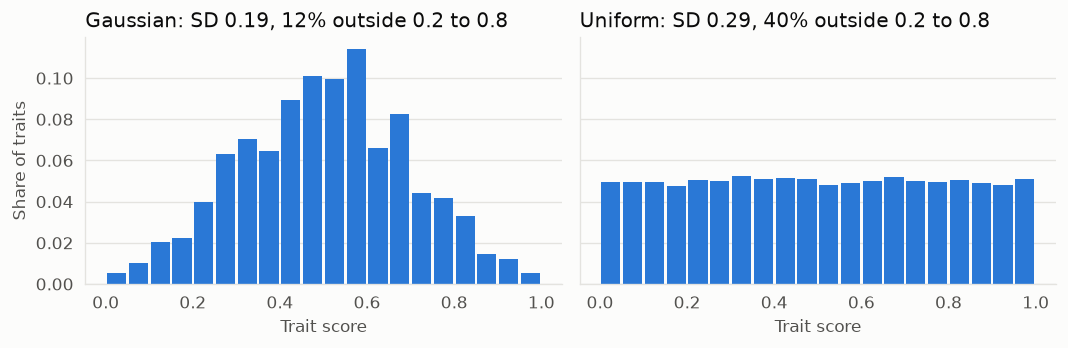

In [3]:
rng = random.Random(SEED)
gaussian_traits = [
    value
    for _ in range(1000)
    for traits in synthetic_personas.generate_scores(rng).values()
    for value in traits.values()
]
uniform_traits = [rng.uniform(0, 1) for _ in gaussian_traits]

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, values, name in zip(axes, [gaussian_traits, uniform_traits], ["Gaussian", "Uniform"]):
    values = np.array(values)
    outer = np.mean((values < 0.2) | (values > 0.8))
    ax.hist(values, bins=bins, color=BLUE, rwidth=0.88, weights=np.ones(len(values)) / len(values))
    ax.set_title(f"{name}: SD {values.std():.2f}, {outer:.0%} outside 0.2 to 0.8")
    ax.set_xlabel("Trait score")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Share of traits")
fig.tight_layout()
plt.show()

## Collect Jev's ratings

Each rater keeps one profile and one target across all four persona conditions, so only the persona differs. Raters are interested in the opposite gender, which gives them plenty of compatible targets.

In [4]:
manager = ProfileManager(ROOT / "main.db", ROOT / "personas.db")
profiles = manager.list_profiles()


def ask_jev(rater, description, target):
    persona = Persona(user_id=rater.user_id, description=description)
    score, raw_output = _call_jev(build_rater_input(rater, persona, target))
    return score, json.loads(raw_output)["input_tokens"]


def collect_results():
    rng = random.Random(SEED)
    raters = rng.sample([p for p in profiles if p.interested_in == {"man": "women", "woman": "men"}[p.gender]], N_RATERS)
    rows = []

    def record(experiment, condition, rater_index, rater, description, target, target_kind=None):
        like, tokens = ask_jev(rater, description, target)
        rows.append({
            "experiment": experiment,
            "condition": condition,
            "rater": rater_index,
            "target_kind": target_kind,
            "like": like,
            "input_tokens": tokens,
        })

    for rater_index, rater in enumerate(raters):
        compatible = [p for p in profiles if is_compatible(rater, p)]
        target = rng.choice(compatible)
        for condition, make_persona in PERSONA_CONDITIONS.items():
            for _ in range(N_PERSONAS):
                record("spread", condition, rater_index, rater, make_persona(rng, rater), target)

        fixed_persona = gaussian_persona(rng, rater)
        for _ in range(N_REPEATS):
            record("spread", "Repeats", rater_index, rater, fixed_persona, target)
        for other_target in rng.sample(compatible, N_TARGETS):
            record("spread", "Different targets", rater_index, rater, fixed_persona, other_target)

        religious = rng.choice([p for p in compatible if p.religion in RELIGIOUS_TARGETS])
        atheist = rng.choice([p for p in compatible if p.religion == "atheist"])
        for condition, description in (("Wants religious", WANTS_RELIGIOUS), ("Wants non-religious", WANTS_NON_RELIGIOUS)):
            record("blunt", condition, rater_index, rater, description, religious, "Religious target")
            record("blunt", condition, rater_index, rater, description, atheist, "Atheist target")
    return pd.DataFrame(rows)


if RERUN_JEV or not RESULTS_PATH.exists():
    results = collect_results()
    results.to_csv(RESULTS_PATH, index=False)
else:
    results = pd.read_csv(RESULTS_PATH)

total_tokens = results["input_tokens"].sum()
print(f"{len(results)} ratings, {total_tokens:,} input tokens, about ${total_tokens / 1e6 * JEV_PRICE_PER_MTOK:.3f}")

384 ratings, 364,865 input tokens, about $0.015


## Result 1: how much does each change move the like probability?

For each rater, this takes the SD of the like probability within a condition, then averages across raters. The interval is a bootstrap 95% interval over the 8 raters.

In [5]:
ORDER = ["Repeats", "Gaussian", "Uniform", "Consistent", "Extreme", "Different targets"]
spread = results[results["experiment"] == "spread"]
per_rater_sd = spread.groupby(["condition", "rater"])["like"].std().unstack("rater").loc[ORDER]


def bootstrap_interval(values, statistic=np.mean, n_samples=10_000, seed=SEED):
    values = np.asarray(values)
    generator = np.random.default_rng(seed)
    samples = generator.choice(values, size=(n_samples, len(values)), replace=True)
    return np.percentile(statistic(samples, axis=1), [2.5, 97.5])


summary = pd.DataFrame({
    "mean_like": spread.groupby("condition")["like"].mean().loc[ORDER],
    "sd_within_rater": per_rater_sd.mean(axis=1),
})
intervals = pd.DataFrame(
    [bootstrap_interval(per_rater_sd.loc[c].values) for c in ORDER], index=ORDER, columns=["ci_low", "ci_high"]
)
summary = summary.join(intervals)
summary["times_noise"] = summary["sd_within_rater"] / summary.loc["Repeats", "sd_within_rater"]
summary["share_of_target_effect"] = summary["sd_within_rater"] / summary.loc["Different targets", "sd_within_rater"]
summary.round(3)

,mean_like,sd_within_rater,ci_low,ci_high,times_noise,share_of_target_effect
condition,,,,,,
Repeats,0.582,0.010,0.008,0.012,1.000,0.127
Gaussian,0.578,0.027,0.019,0.035,2.655,0.336
Uniform,0.551,0.043,0.032,0.053,4.207,0.533
Consistent,0.558,0.024,0.019,0.028,2.325,0.295
Extreme,0.553,0.037,0.032,0.040,3.599,0.456
Different targets,0.596,0.080,0.062,0.099,7.892,1.000


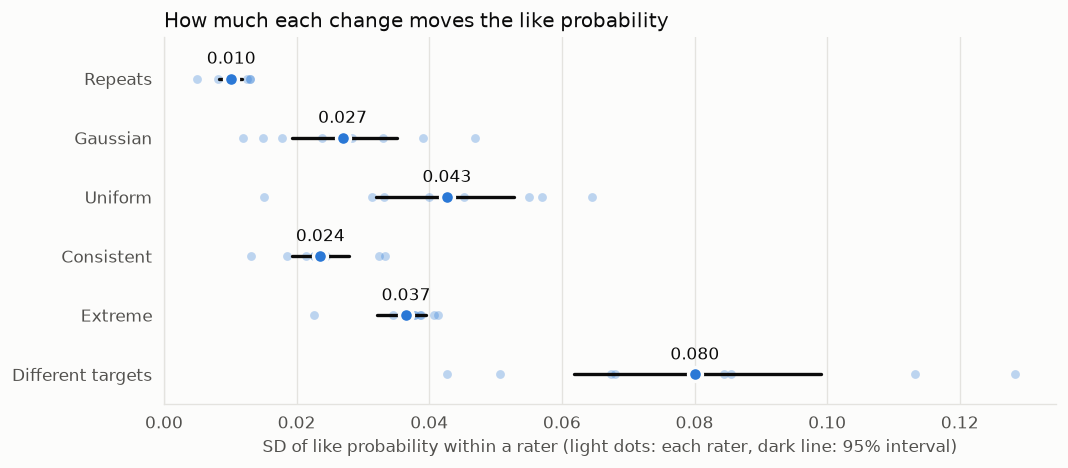

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
positions = np.arange(len(ORDER))[::-1]
for position, condition in zip(positions, ORDER):
    row = summary.loc[condition]
    ax.scatter(per_rater_sd.loc[condition], [position] * N_RATERS, s=28, color=BLUE, alpha=0.3, linewidths=0)
    ax.plot([row["ci_low"], row["ci_high"]], [position, position], color=INK, linewidth=2, solid_capstyle="round")
    ax.scatter(row["sd_within_rater"], position, s=70, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(f"{row['sd_within_rater']:.3f}", (row["sd_within_rater"], position), xytext=(0, 9), textcoords="offset points", ha="center", color=INK)
ax.set_yticks(positions, ORDER)
ax.set_ylim(-0.5, len(ORDER) - 0.3)
ax.set_xlabel("SD of like probability within a rater (light dots: each rater, dark line: 95% interval)")
ax.set_xlim(left=0)
ax.grid(axis="y", visible=False)
ax.set_title("How much each change moves the like probability")
fig.tight_layout()
plt.show()

### Is uniform better than Gaussian?

This pairs the two conditions by rater, since each rater saw the same target under both. An interval that excludes 0 suggests a real difference, though 8 raters is a small sample.

In [7]:
comparisons = []
for condition in ["Uniform", "Consistent", "Extreme"]:
    difference = per_rater_sd.loc[condition] - per_rater_sd.loc["Gaussian"]
    low, high = bootstrap_interval(difference.values)
    comparisons.append({
        "versus_gaussian": condition,
        "sd_difference": difference.mean(),
        "ci_low": low,
        "ci_high": high,
        "raters_higher": int((difference > 0).sum()),
    })
pd.DataFrame(comparisons).set_index("versus_gaussian").round(3)

,sd_difference,ci_low,ci_high,raters_higher
versus_gaussian,,,,
Uniform,0.016,0.003,0.029,6
Consistent,-0.003,-0.012,0.005,4
Extreme,0.010,0.000,0.019,6


## Result 2: do personas shift scores, or only spread them?

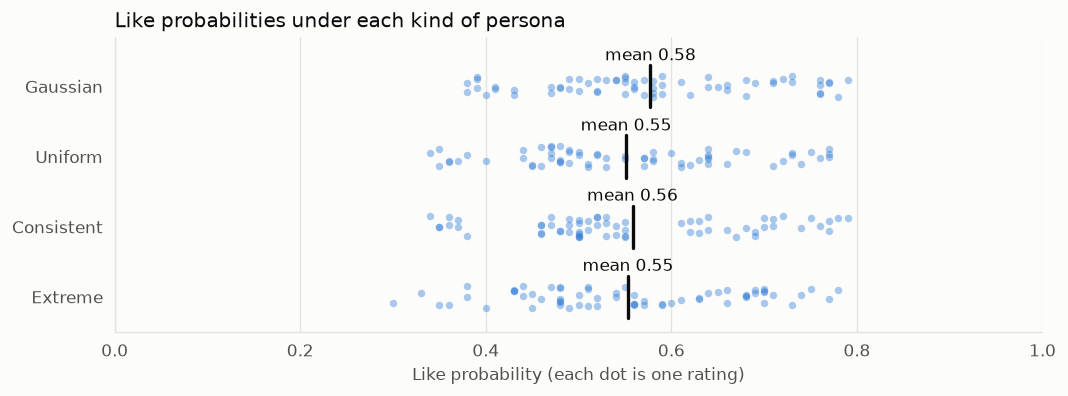

In [8]:
conditions = ["Gaussian", "Uniform", "Consistent", "Extreme"]
fig, ax = plt.subplots(figsize=(9, 3.4))
jitter = np.random.default_rng(SEED)
for position, condition in zip(np.arange(len(conditions))[::-1], conditions):
    values = spread[spread["condition"] == condition]["like"]
    ax.scatter(values, position + jitter.uniform(-0.16, 0.16, len(values)), s=20, color=BLUE, alpha=0.4, linewidths=0)
    ax.plot([values.mean()] * 2, [position - 0.3, position + 0.3], color=INK, linewidth=2, solid_capstyle="round")
    ax.annotate(f"mean {values.mean():.2f}", (values.mean(), position + 0.3), xytext=(0, 3), textcoords="offset points", ha="center", color=INK)
ax.set_yticks(np.arange(len(conditions))[::-1], conditions)
ax.set_ylim(-0.5, len(conditions) - 0.3)
ax.set_xlim(0, 1)
ax.set_xlabel("Like probability (each dot is one rating)")
ax.grid(axis="y", visible=False)
ax.set_title("Like probabilities under each kind of persona")
fig.tight_layout()
plt.show()

## Result 3: does Jev follow a preference written in words?

Each rater is given one of two opposite sentences and shown a religious and an atheist target. If Jev uses the persona, the bars should flip between the two targets.

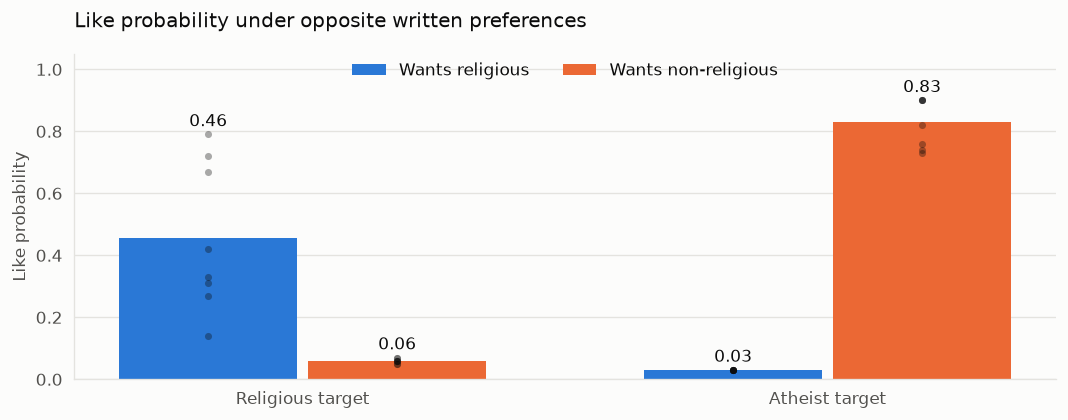

Mean effect of flipping the preference, per target:
  Religious target: 0.396 in the expected direction, 8 of 8 raters
  Atheist target: 0.801 in the expected direction, 8 of 8 raters


target_kind,Atheist target,Religious target
condition,,
Wants non-religious,0.831,0.060
Wants religious,0.030,0.456


In [9]:
blunt = results[results["experiment"] == "blunt"]
target_kinds = ["Religious target", "Atheist target"]
preferences = [("Wants religious", BLUE), ("Wants non-religious", ORANGE)]

fig, ax = plt.subplots(figsize=(9, 3.6))
width = 0.34
for offset, (preference, color) in zip([-width / 2 - 0.01, width / 2 + 0.01], preferences):
    for index, kind in enumerate(target_kinds):
        values = blunt[(blunt["condition"] == preference) & (blunt["target_kind"] == kind)]["like"]
        ax.bar(index + offset, values.mean(), width, color=color, label=preference if index == 0 else None)
        ax.scatter([index + offset] * len(values), values, s=18, color=INK, alpha=0.35, linewidths=0, zorder=3)
        ax.annotate(f"{values.mean():.2f}", (index + offset, values.max()), xytext=(0, 5), textcoords="offset points", ha="center")
ax.set_xticks(range(len(target_kinds)), target_kinds)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Like probability")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", ncols=2, bbox_to_anchor=(0.5, 1.02))
ax.set_title("Like probability under opposite written preferences", pad=16)
fig.tight_layout()
plt.show()

blunt_table = blunt.pivot_table(index="condition", columns="target_kind", values="like").round(3)
blunt_gaps = blunt.pivot_table(index="rater", columns=["condition", "target_kind"], values="like")
print("Mean effect of flipping the preference, per target:")
for kind, sign in (("Religious target", 1), ("Atheist target", -1)):
    gap = sign * (blunt_gaps[("Wants religious", kind)] - blunt_gaps[("Wants non-religious", kind)])
    print(f"  {kind}: {gap.mean():.3f} in the expected direction, {int((gap > 0).sum())} of {N_RATERS} raters")
blunt_table

## What this shows

**Jev does respond to personas, but mostly when they're written in words.** Flipping a written preference moved the like probability by 0.40 for religious targets and 0.80 for atheist targets, in the expected direction for all 8 raters. Changing trait numbers only moved it by an SD of 0.02 to 0.04. So the weak link looks like the trait-number format, not Jev itself.

| Question | Answer |
| --- | --- |
| **Does uniform add variation?** | Somewhat. The persona effect rose from 0.027 to 0.043, about 1.6 times, and 6 of 8 raters went up. |
| **Is more variation in the numbers the answer?** | Probably not. Extreme traits (0.037) did no better than uniform, even though they have the most variation numbers can have. |
| **Do personas that fit the profile matter more?** | No sign of it. Consistent personas scored 0.024 against 0.027 for Gaussian. This doesn't test whether they'd help a matcher learn. |
| **Is the persona effect larger than noise?** | Yes. Repeats had an SD of 0.010, so even Gaussian personas are about 2.7 times noise, but all trait conditions stay well below the target effect of 0.080. |

**Limits of this test:**
- It's a small sample: 8 raters with one target each and 8 personas per condition, so the intervals are wide.
- The written preferences are absolute ("would not date"), about religion only, and replace the whole persona. Softer or broader preferences will probably move scores less.
- The two measures differ. The trait conditions report an SD across personas, and the written preferences report a gap between two opposites, so compare their sizes loosely.

**Recommendation:** write personas as stated preferences rather than trait numbers. Trait scores could still be turned into sentences, so a uniform draw could drive how varied they are. Test softer wording in this notebook before regenerating `personas.db`.